# Respuesta MT y una decisión QC

**Pregunta:** ¿Qué permite afirmar el tensor medido cl061 si falla la condición necesaria 1D?

**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.



## Objetivos

Pregunta: ¿Qué diagnósticos del cl061 medido se pueden usar cuando falla su filtro tensorial necesario para 1D?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.



## Datos

Registro medido solo QC y artefacto sintético de calibración separado; no mezcle estas clases de evidencia.


## Método

Clear Lake `cl061` es un conjunto medido de terreno con 42 frecuencias y verdad del subsuelo desconocida. Su recibo falla la prueba necesaria de consistencia tensorial 1D; permanece **solo para QC** y no debe ajustarse con la inversa estratificada. Esta lección aplica directamente al tensor y las incertidumbres marginales versionadas los diagnósticos implementados `mt_field_qc.tensor_gate` y `phase_tensor_diagnostic`. También inspecciona el tipper suministrado, evidencia auxiliar que nunca se usa como entrada del solver 1D.

Se conserva la rotación EDI en el marco recibido (`rotation_action: none`); no se intenta una rerrotación sin covarianza. El módulo comprueba que la distancia geométrica a un tensor 1D ideal sea invariante ante un giro de 90°, propiedad diagnóstica y no reprocesamiento de esta estación. La varianza del tipper está explícitamente sin interpretar en el recibo; por ello se grafican solo magnitudes de componentes y frecuencias faltantes. No se calculan residuos normalizados ni barras de error del tipper.

Con `exp(+iωt)`, `Z=E/H` está en Ω, la resistividad aparente `ρₐ=|Z|²/(μ₀ω)` en Ω·m, la fase en grados y el período `T=1/f` en segundos. La prueba es un nulo necesario de consistencia, no una demostración de dimensionalidad. Un fallo no se corrige ajustando una inversión 1D.
### Límite de elegibilidad de cl061

El tensor medido de 42 períodos falla filtros 1D guardado y recalculado; tensor de fase y tipper siguen como evidencia QC auxiliar.


In [1]:
# Aplicar diagnósticos QC implementados al tensor medido; no ajustar cl061.
import json, sys
from pathlib import Path
import numpy as np
from importlib.metadata import version

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from mt_field_qc import tensor_gate, phase_tensor_diagnostic

case = json.loads((root / "data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
f = np.asarray(case["frequencies_hz"], float)
period = 1 / f
z = np.asarray(case["tensor"]["real"]) + 1j * np.asarray(case["tensor"]["imag"])
sigma = np.asarray(case["tensor"]["sigma"], float)
gate = tensor_gate(z, sigma**2)  # El recibo guarda SD marginal; la función QC recibe varianza.
phase_qc = phase_tensor_diagnostic(z)
tip = case["metadata"]["tipper"]
print("Versiones:", {name: version(name) for name in ("numpy", "matplotlib", "scipy")})
print("Fuente medida:", case["id"], case["source_kind"], "N=", len(f), "verdad=", case['truth'])
print(
    "Elegibilidad:",
    case["one_d_inversion_eligible"],
    "prueba guardada:",
    case["compatibility"]["passes_screen"],
    "recalculada:",
    gate["passes"],
)
print("Puntajes QC:", list(gate["per_period_normalized"]), "límite:", gate['threshold'])
print("Error máx. de invariancia geométrica al cuarto de giro:", gate["quarter_turn_invariance_max_abs_error"])


Versiones: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Fuente medida: cl061 measured EDI transfer functions N= 42 verdad= None
Elegibilidad: False prueba guardada: False recalculada: False
Puntajes QC: ['xx', 'yy', 'antisymmetry'] límite: 3.0
Error máx. de invariancia geométrica al cuarto de giro: 1.1102230246251565e-16


### Inspeccionar diagnósticos de tensor de fase y tipper

La compuerta invariante de impedancia informa por separado sus puntajes por período y la elegibilidad. Aquí se muestran los campos del tensor de fase y del tipper; no cambian el estado QC-only de Clear Lake.

In [2]:
# Inspeccionar diagnósticos de tensor de fase y tipper.
print(
    "Períodos utilizables del tensor de fase:",
    phase_qc["usable_periods"],
    "desviación escalar mediana:",
    phase_qc["median_scalar_departure"],
)
print(
    "Tipper presente:",
    tip["present"],
    "usado por inversa 1D:",
    tip["used_in_1d_inversion"],
    "varianza:",
    tip["raw_variance_convention"],
)


Períodos utilizables del tensor de fase: 42 desviación escalar mediana: 0.257651139958079
Tipper presente: True usado por inversa 1D: False varianza: uninterpreted EDI native variance


### Diagnóstico 2 — Recalcular QC tensorial e inspeccionar el tipper auxiliar

El panel superior derecho muestra las tres verificaciones necesarias de 1D normalizadas por ruido. La superposición inferior derecha presenta desviación escalar del tensor de fase y magnitud bruta del tipper; son indicios QC, no objetivos de una inversa 1D. Los períodos faltantes del tipper siguen faltantes.

Grafique primero impedancia y compuerta de consistencia 1D; luego agregue tensor de fase y diagnóstico del tipper.

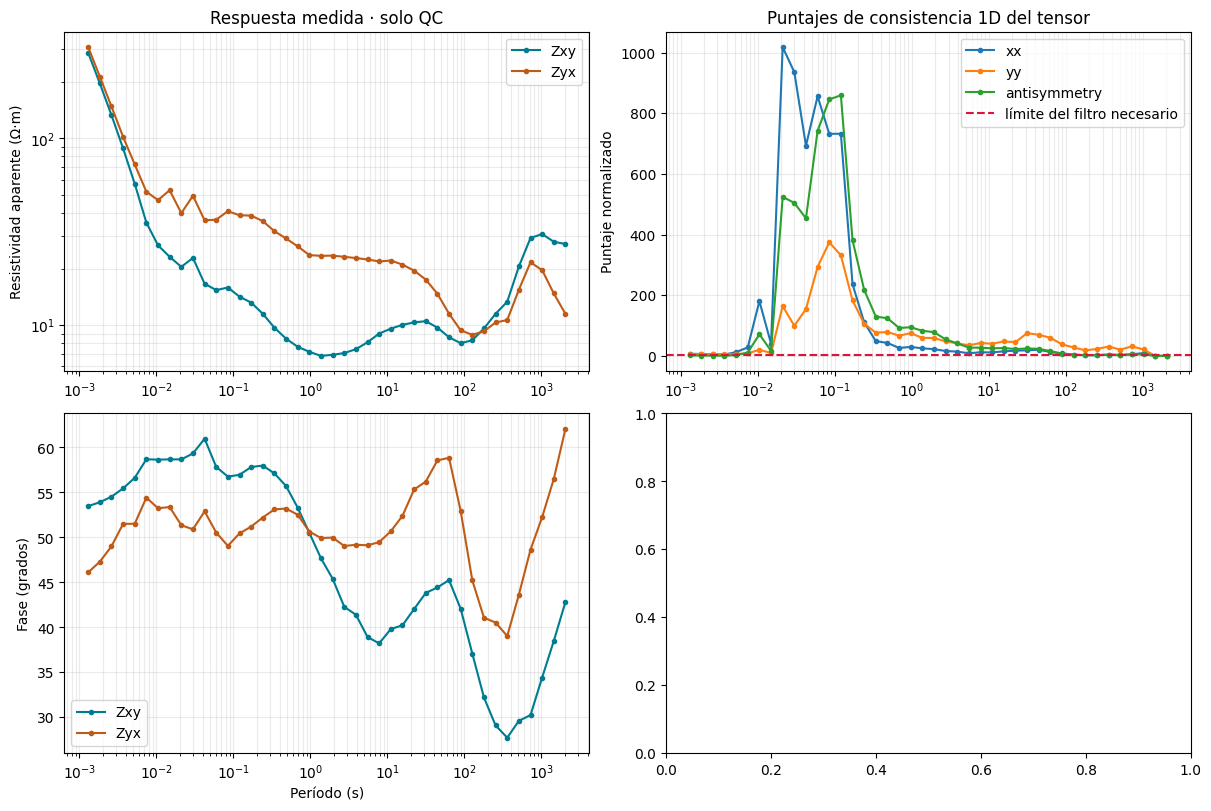

In [3]:
# Grafique la impedancia y la condición necesaria de tensor 1D.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for name, color in (("xy", "#007c91"), ("yx", "#bf5b17")):
    response = case["observed"][name]
    ax[0, 0].loglog(period, response["apparent"], ".-", label="Z" + name, color=color)
    ax[1, 0].semilogx(period, response["phase"], ".-", label="Z" + name, color=color)
ax[0, 0].set_ylabel("Resistividad aparente (Ω·m)")
ax[1, 0].set_ylabel("Fase (grados)")
ax[1, 0].set_xlabel("Período (s)")
for axis in (ax[0, 0], ax[1, 0]):
    axis.grid(True, which="both", alpha=0.25)
    axis.legend()
ax[0, 0].set_title("Respuesta medida · solo QC")
for key, score in gate["per_period_normalized"].items():
    ax[0, 1].semilogx(period, score, ".-", label=key)
ax[0, 1].axhline(gate['threshold'], color="crimson", ls="--", label="límite del filtro necesario")
ax[0, 1].set_title("Puntajes de consistencia 1D del tensor")
ax[0, 1].set_ylabel("Puntaje normalizado")
ax[0, 1].legend()
ax[0, 1].grid(True, which="both", alpha=0.25)


El primer panel compara ambas orientaciones de impedancia medida y la compuerta necesaria 1D. La siguiente celda agrega desviación del tensor de fase y magnitudes crudas del tipper; su varianza no tiene interpretación declarada y no se convierte en incertidumbre.

In [4]:
# Añada diagnósticos del tensor de fase y magnitudes brutas del tipper sin interpretar su varianza.
pt = phase_qc["per_period"]
pt_period = np.asarray([period[row["source_index"]] for row in pt])
pt_departure = np.asarray([row["scalar_departure"] for row in pt])
ax[1, 0].set_title("Respuesta de fase medida")
ax[1, 1].semilogx(pt_period, pt_departure, "o", ms=4, color="#7651a8")
ax[1, 1].set_title("Desviación escalar del tensor de fase")
ax[1, 1].set_ylabel("Relative departure (dimensionless)")
ax[1, 1].set_xlabel("Período (s)")
ax[1, 1].grid(True, which="both", alpha=0.25)
tx = np.asarray(tip["components"]["X"]["real"], dtype=float)
tx = tx + 1j * np.asarray(tip["components"]["X"]["imag"], dtype=float)
ty = np.asarray(tip["components"]["Y"]["real"], dtype=float)
ty = ty + 1j * np.asarray(tip["components"]["Y"]["imag"], dtype=float)
axis = ax[1, 1].twinx()
axis.semilogx(period, np.abs(tx), "s", ms=3, color="#007c91", alpha=0.65, label="|Tx|")
axis.semilogx(period, np.abs(ty), "^", ms=3, color="#bf5b17", alpha=0.65, label="|Ty|")
axis.set_ylabel("Magnitud del tipper (adimensional)")
handles, labels = ax[1, 1].get_legend_handles_labels()
tipper_handles, tipper_labels = axis.get_legend_handles_labels()
axis.legend(handles + tipper_handles, labels + tipper_labels, fontsize=8, loc="best")
fig.suptitle("Evidencia medida Clear Lake cl061 — solo QC; sin ajuste estratificado")
plt.show()
print("Frecuencias faltantes del tipper (Hz):", tip["missing_frequency_hz"])
print("La varianza del tipper no está interpretada; no se muestran barras de incertidumbre del tipper.")


Frecuencias faltantes del tipper (Hz): [0.0004882812, 0.0006915263]
La varianza del tipper no está interpretada; no se muestran barras de incertidumbre del tipper.


Recalcule la prueba necesaria con desviaciones estándar dobles.

In [5]:
# Recalcule la prueba necesaria con desviaciones estándar dobles.
looser_gate = tensor_gate(z, (2 * sigma) ** 2)
print("WRMS con 2× sigma:", looser_gate["wrms"])


WRMS con 2× sigma: {'xx': 160.11663013231475, 'yy': 54.753939889373655, 'antisymmetry': 133.80001937595154}


Recalcule con la mitad de desviación para mostrar sensibilidad QC.

In [6]:
# Recalcule con la mitad de desviación para mostrar sensibilidad QC.
tighter_gate = tensor_gate(z, (0.5 * sigma) ** 2)
print("WRMS con 0,5× sigma:", tighter_gate["wrms"])


WRMS con 0,5× sigma: {'xx': 640.466520529259, 'yy': 219.01575955749462, 'antisymmetry': 535.2000775038061}


## Resultados

El conjunto permanece solo-QC porque falla el filtro de elegibilidad 1D; sus diagnósticos de tensor y tipper no son una inversión estratificada. Los períodos faltantes del tipper siguen faltantes.

**Respuesta:** Los 42 períodos de impedancia están disponibles para el cálculo del tensor de fase, cuya desviación escalar mediana es 0.257651. Fallan tanto el filtro guardado como la elegibilidad 1D recalculada; faltan dos frecuencias de tipper y su incertidumbre no está interpretada.


## Resumen

Este EDI medido solo permite revisión QC. El filtro fallido excluye cl061 de la inversión 1D; ni la desviación del tensor de fase ni la cobertura incompleta de tipper revierten esa decisión o aportan verdad del subsuelo.



## Referencias

- [MTpy v2](https://github.com/MTgeophysics/mtpy-v2)
- [Datos magnetotelúricos USGS de Clear Lake](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)



El registro medido Clear Lake cl061 se conserva únicamente como evidencia QC. El tensor comprometido y sus varianzas marginales son entradas de la compuerta 1D necesaria y del diagnóstico del tensor de fase. La compuerta normaliza desviaciones diagonales y de antisimetría en todas las frecuencias disponibles. Si falla, no significa que el EDI carezca de valor; significa que no es elegible para esta inversa estratificada según la regla declarada. No se deben ajustar ventanas hasta forzar el aprobado ni pasar cl061 al ajuste sintético. Se preservan estado medido, grilla original, tipper incompleto y veredicto negativo.
La recurrencia directa MT utiliza impedancia compleja en capas finitas. El ajuste en log-resistividad mantiene positividad. El experimento separa frecuencias de validación antes de formar la máscara; todos los métodos usan mismas observaciones activas, modelo inicial, espesores fijos, límites e incertidumbre. Compare residuales complejos activos y retenidos, no solo curvas de resistividad aparente. El barrido de beta cambia el peso de suavidad y puede intercambiar ajuste por simplicidad del modelo. Un residual retenido que empeora mientras mejora entrenamiento muestra una consecuencia predictiva. Como el espesor permanece fijado, las interfaces son supuestos de entrada, no parámetros recuperados.